# DATA ANALYST

Muhammad Yazid Sukindi - 10121941 - 4KA03

Juni, 13 Juni 2025

Sesi 1 dan 2

## Skema Data Analyst

No.	Kode Unit	Nama Unit


1.   J.62DMI00.004.1	Mengumpulkan Data
2.   J.62DMI00.005.1	Menelaah Data
3.   J.62DMI00.006.1	Memvalidasi Data
4.   J.62DMI00.007.1	Menentukan Objek Data
5.   J.62DMS00.001.1	Mengidentifikasi Kebutuhan Pengelolaan Data untuk Proses Bisnis
6.   J.62DMS00.015.1	Membuat Business Intelligence
7.   M.70BDA00.013.1	Menyusun Laporan Hasil Analisis

## CRISMP DM

CRISP-DM adalah metodologi standar dalam proses data mining, terdiri dari 6 fase utama:

1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modeling
5. Evaluation
6. Deployment

## Scrapping Data = J.62DMI00.004.1 Mengumpulkan Data
Proses mengumpulkan data dilakukan dengan mengambil data melalui pihak ketiga penyedia dataset yaitu kaggle

langkah pengumpulan data melalui kaggle:


1. Download library kaggle
2. Download Dataset dari Kaggle
3. Ekstrak file Zip yang sudah di download

# library

In [ ]:
#Untuk menavigasi direktory
import os
#library tambahan untuk memuat drive
from google.colab import drive
# melakukan cek arus kecepatan import data
from time import time

# Membaca ddata dari file di Google Drive

In [ ]:
#menghubungkan notebook colab ke google drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#menghubungkan colab agar pencarian file tertuju ke dalam dalam Folder DataA_LSP
path = '/content/drive/MyDrive/DataA_LSP'
os.chdir(path)

## 2. Data Understanding = J.62DMI00.005.1	Menelaah Data

Langkah-langkah:

*   Import Library
*   Load Dataset
*   Check the general Information



Import Library

In [ ]:
#import library untuk kebutuhan analisis
import numpy as np
import pandas as pd
#import library untuk kebutuhan visualisasi
import seaborn as sns
import matplotlib.pyplot as plt

Load dataset

In [ ]:
# membaca file serta mengetahui berapa lama waktu yang di butuhkan untuk menyelesaikan tahap ini
# Memulai timer
start = time()

# Membaca file Excel
df = pd.read_csv("netflix1.csv")

# Menghentikan timer
end = time()

# Menampilkan waktu yang dibutuhkan
print("Done loading all datasets in {:.3f}s".format(end - start))

Done loading all datasets in 0.305s


In [ ]:
df

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
...,...,...,...,...,...,...,...,...,...,...
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV


## Check the General Information J.62DMI00.007.1	Menentukan Objek Data

---



Melihat informasi Umum Ini digunakan untuk mengenali data kita.

In [ ]:
#melihat ukuran data
df.shape

(8790, 10)

In [ ]:
#melihat keseluruhan dari isi data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


Output diatas menunjukan bahwa data berisi 8790 baris dan 10 kolom


*   Terdapat 8 kolom bertipekan object dari seluruh data selain release_year dan 1 bertipekan interger yaitu release_year





## 3. Data Preparation = J.62DMI00.006.1	Memvalidasi Data

**Menangangani missing value**

Missing value adalah data yang hilang atau tidak tersedia dalam suatu dataset. Ini bisa terjadi karena berbagai alasan seperti kesalahan pengisian, ketidakmampuan untuk mendapatkan informasi, atau data yang memang tidak ada

In [ ]:
#Mengecek missing values
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0


Dapat dilihat dari output diatas, tiap kolom bernilai 0 yang artinya tidak ada missing value di tiap kolom pada data

Konversi Tipe Data

Beberapa kolom pada dataset mengalami perubahan tipe data untuk meningkatkan akurasi representasi serta efisiensi analisis. Misalnya, kolom type, country, dan rating dikonversi dari tipe object ke category karena masing-masing hanya memiliki sejumlah nilai unik terbatas dan bersifat kategorikal. Konversi ini bertujuan untuk menghemat penggunaan memori dan mempercepat proses analisis data.

Kolom date_added diubah dari object menjadi datetime64[ns] agar dapat digunakan dalam analisis berbasis waktu, seperti tren penambahan film atau serial berdasarkan bulan dan tahun.

Kolom duration awalnya berbentuk teks gabungan (misalnya "90 min" atau "1 Season"), sehingga dipisahkan menjadi dua kolom baru: duration_int bertipe numerik (int) dan duration_type bertipe kategori (category). Pemisahan ini dilakukan untuk memudahkan analisis durasi tayangan berdasarkan nilai dan jenisnya, serta menyederhanakan proses visualisasi atau segmentasi data.

Perubahan tipe data ini dilakukan secara selektif untuk meningkatkan kualitas data dan memperlancar proses eksplorasi maupun visualisasi dalam tahap analisis berikutnya.

# Melakukan konversi tipe data

In [ ]:
# Misalnya df adalah nama DataFrame kamu
df['type'] = df['type'].astype('category')
df['country'] = df['country'].astype('category')
df['rating'] = df['rating'].astype('category')

In [ ]:
# Ubah date_added ke datetime
df['date_added'] = pd.to_datetime(df['date_added'])

In [ ]:
# Pisahkan durasi jadi dua kolom (durasi dan satuan: min / Season)
df[['duration_int', 'duration_type']] = df['duration'].str.extract(r'(\d+)\s*(\w+)')
df['duration_int'] = pd.to_numeric(df['duration_int'], errors='coerce')
df['duration_type'] = df['duration_type'].astype('category')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   show_id        8790 non-null   object        
 1   type           8790 non-null   category      
 2   title          8790 non-null   object        
 3   director       8790 non-null   object        
 4   country        8790 non-null   category      
 5   date_added     8790 non-null   datetime64[ns]
 6   release_year   8790 non-null   int64         
 7   rating         8790 non-null   category      
 8   duration       8790 non-null   object        
 9   listed_in      8790 non-null   object        
 10  duration_int   8790 non-null   int64         
 11  duration_type  8790 non-null   category      
dtypes: category(4), datetime64[ns](1), int64(2), object(5)
memory usage: 587.5+ KB


In [ ]:
df

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_int,duration_type
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min
...,...,...,...,...,...,...,...,...,...,...,...,...
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,2017-01-17,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas",2,Seasons
8786,s8798,TV Show,Zak Storm,Not Given,United States,2018-09-13,2016,TV-Y7,3 Seasons,Kids' TV,3,Seasons
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,2016-12-15,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ...",1,Season
8788,s8784,TV Show,Yoko,Not Given,Pakistan,2018-06-23,2016,TV-Y,1 Season,Kids' TV,1,Season


**Data Outlier**

Data outlier adalah observasi atau titik data yang secara signifikan berbeda dari sebagian besar data lainnya dalam sebuah kumpulan data. Keberadaannya dapat disebabkan oleh kesalahan pengukuran, kesalahan entri data, atau memang merepresentasikan variasi yang tidak biasa namun valid.


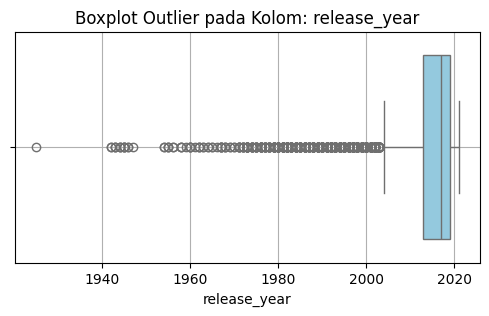

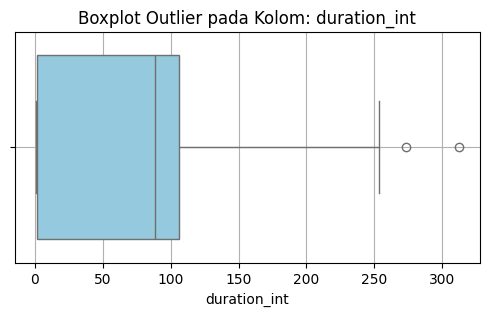

In [ ]:
# Ambil hanya kolom numerik
numeric_cols = df.select_dtypes(include='number').columns

# Loop setiap kolom numerik
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot Outlier pada Kolom: {col}')
    plt.xlabel(col)
    plt.grid(True)
    plt.show()

Melakukan perhitungan apakah outlier perlu di mutasi atau tidak

In [ ]:
# Hitung IQR
Q1 = df['release_year'].quantile(0.25)
Q3 = df['release_year'].quantile(0.75)
IQR = Q3 - Q1

# Hitung batas bawah dan atas
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# Filter data agar hanya menyisakan yang dalam rentang IQR
df_cleaned = df[(df['release_year'] >= batas_bawah) & (df['release_year'] <= batas_atas)]


melakukan cek outlier yang telah di mutasi

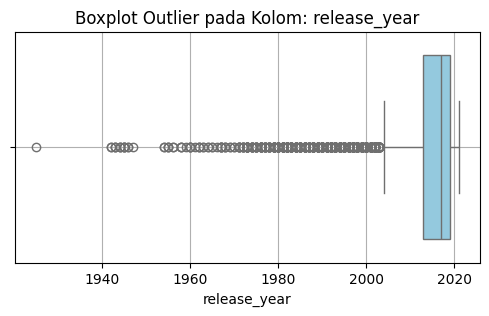

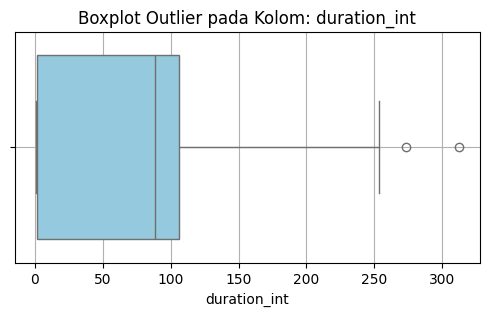

In [ ]:
# Ambil hanya kolom numerik
numeric_cols = df.select_dtypes(include='number').columns

# Loop setiap kolom numerik
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot Outlier pada Kolom: {col}')
    plt.xlabel(col)
    plt.grid(True)
    plt.show()

penjelasan di atas mendapat kan hasil kalau outlier masih dalam range aman maka keputusan data tidak perlu di mutasi

**Data Duplikat**

kondisi di mana satu atau beberapa entri data memiliki nilai yang sama di seluruh kolom atau atribut pada suatu dataset. Data duplikat dapat mempengaruhi akurasi analisis data, kinerja operasional database, dan kualitas data secara keseluruhan.

In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
8785,False
8786,False
8787,False
8788,False


Secara keseluruhan hasil output menunjukan tidak terdapatnya data duplikat pada baris data secara keseluruhan

**Penghapusan Kolom**


Kolom show_id berisi identifier unik untuk setiap entri dan tidak memiliki hubungan matematis atau logis dengan karakteristik lain seperti type, duration_int, atau rating. Oleh karena itu, menyertakan kolom show_id dalam pemodelan machine learning dapat menyebabkan overfitting, karena model mungkin menghafal nilai unik tersebut tanpa belajar pola yang relevan. Selain itu, keberadaan kolom ini dapat memperlambat proses pelatihan tanpa memberikan manfaat nyata. Dengan demikian, kolom show_id sebaiknya dihapus sebelum proses pemodelan.

In [ ]:
df.drop(columns=['show_id'], inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   type           8790 non-null   category      
 1   title          8790 non-null   object        
 2   director       8790 non-null   object        
 3   country        8790 non-null   category      
 4   date_added     8790 non-null   datetime64[ns]
 5   release_year   8790 non-null   int64         
 6   rating         8790 non-null   category      
 7   duration       8790 non-null   object        
 8   listed_in      8790 non-null   object        
 9   duration_int   8790 non-null   int64         
 10  duration_type  8790 non-null   category      
dtypes: category(4), datetime64[ns](1), int64(2), object(4)
memory usage: 518.8+ KB


# Exploratory Data Analysis (EDA)

In [ ]:
#cek nama kolom
df.columns

Index(['type', 'title', 'director', 'country', 'date_added', 'release_year',
       'rating', 'duration', 'listed_in', 'duration_int', 'duration_type'],
      dtype='object')

In [ ]:
# 1. Info umum
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   type           8790 non-null   category      
 1   title          8790 non-null   object        
 2   director       8790 non-null   object        
 3   country        8790 non-null   category      
 4   date_added     8790 non-null   datetime64[ns]
 5   release_year   8790 non-null   int64         
 6   rating         8790 non-null   category      
 7   duration       8790 non-null   object        
 8   listed_in      8790 non-null   object        
 9   duration_int   8790 non-null   int64         
 10  duration_type  8790 non-null   category      
dtypes: category(4), datetime64[ns](1), int64(2), object(4)
memory usage: 518.8+ KB


In [ ]:
# 2. Statistik deskriptif untuk kolom numerik
print("\nStatistik Deskriptif:")
print(df.describe())


Statistik Deskriptif:
                          date_added  release_year  duration_int
count                           8790   8790.000000   8790.000000
mean   2019-05-17 21:44:01.638225408   2014.183163     69.934471
min              2008-01-01 00:00:00   1925.000000      1.000000
25%              2018-04-06 00:00:00   2013.000000      2.000000
50%              2019-07-03 00:00:00   2017.000000     88.500000
75%              2020-08-19 18:00:00   2019.000000    106.000000
max              2021-09-25 00:00:00   2021.000000    312.000000
std                              NaN      8.825466     50.794433


In [ ]:
# 3. Cek nilai unik dan distribusinya
print("\nDistribusi nilai pada kolom 'type':")
print(df['type'].value_counts())

print("\nDistribusi nilai pada kolom 'rating':")
print(df['rating'].value_counts())


Distribusi nilai pada kolom 'type':
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Distribusi nilai pada kolom 'rating':
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


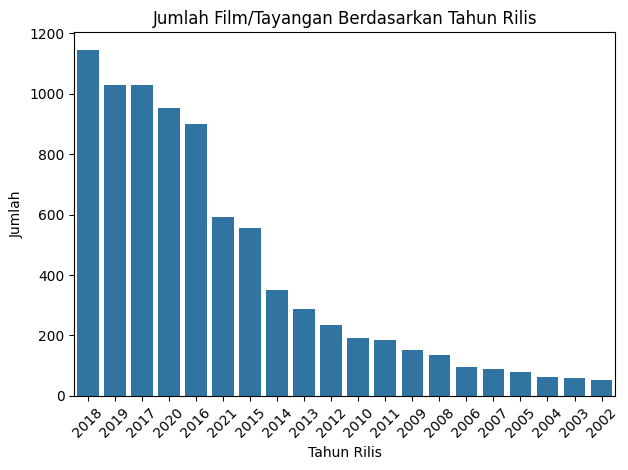

In [ ]:
# 4. Jumlah rilis film berdasarkan tahun
plt.figure()
sns.countplot(data=df, x='release_year', order=df['release_year'].value_counts().index[:20])
plt.xticks(rotation=45)
plt.title('Jumlah Film/Tayangan Berdasarkan Tahun Rilis')
plt.xlabel('Tahun Rilis')
plt.ylabel('Jumlah')
plt.tight_layout()
plt.show()

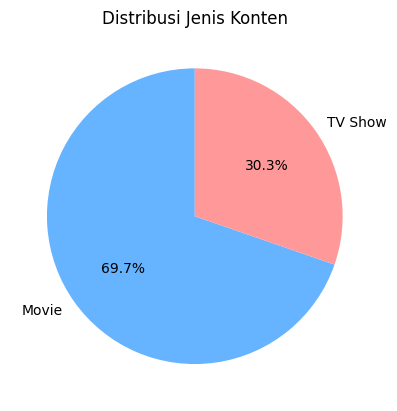

In [ ]:
# 5. Distribusi jenis konten
plt.figure()
df['type'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['#66b3ff','#ff9999'])
plt.title('Distribusi Jenis Konten')
plt.ylabel('')
plt.show()

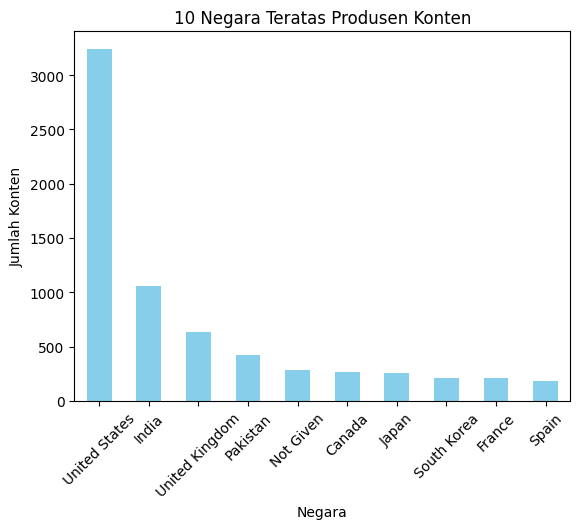

In [ ]:
# 6. 10 negara terbanyak memproduksi konten
plt.figure()
df['country'].value_counts().head(10).plot(kind='bar', color='skyblue')
plt.title('10 Negara Teratas Produsen Konten')
plt.xlabel('Negara')
plt.ylabel('Jumlah Konten')
plt.xticks(rotation=45)
plt.show()

/tmp/ipython-input-31-1984573878.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='rating', order=df['rating'].value_counts().index, palette='viridis')


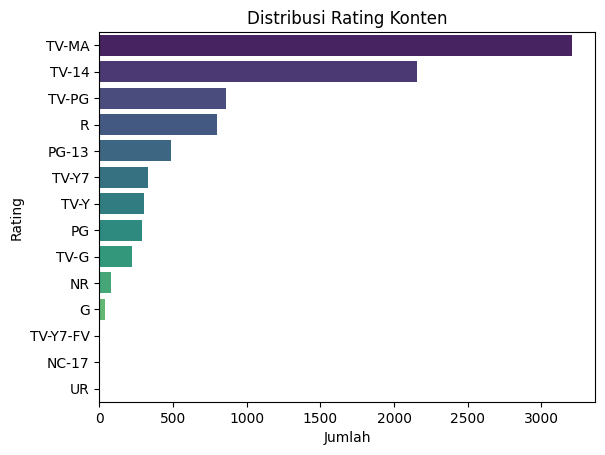

In [ ]:
# 7. Distribusi rating
plt.figure()
sns.countplot(data=df, y='rating', order=df['rating'].value_counts().index, palette='viridis')
plt.title('Distribusi Rating Konten')
plt.xlabel('Jumlah')
plt.ylabel('Rating')
plt.show()

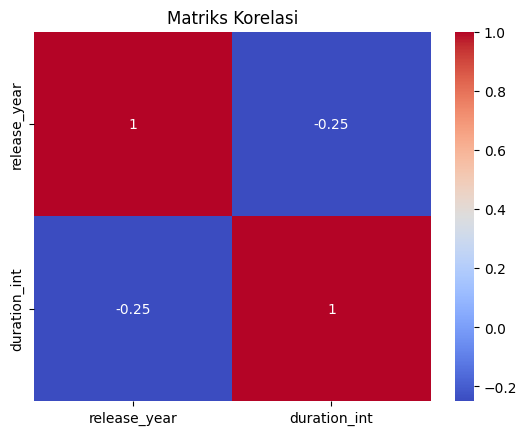

In [ ]:
# 8. Korelasi kolom numerik
plt.figure()
sns.heatmap(df[['release_year', 'duration_int']].corr(), annot=True, cmap='coolwarm')
plt.title('Matriks Korelasi')
plt.show()

/tmp/ipython-input-33-822020732.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='type', y='duration_int', palette='Set2')


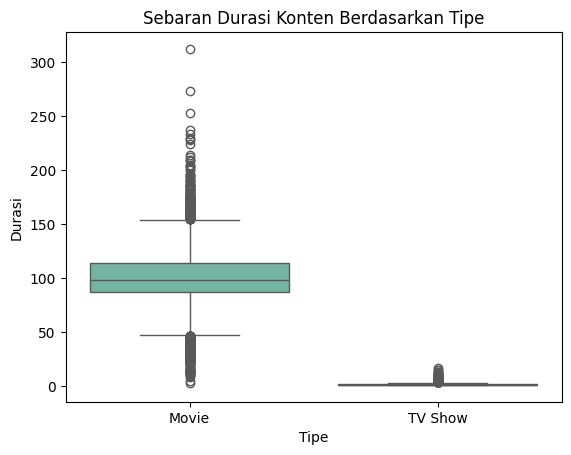

In [ ]:
# 9. Distribusi durasi konten berdasarkan tipe
plt.figure()
sns.boxplot(data=df, x='type', y='duration_int', palette='Set2')
plt.title('Sebaran Durasi Konten Berdasarkan Tipe')
plt.xlabel('Tipe')
plt.ylabel('Durasi')
plt.show()

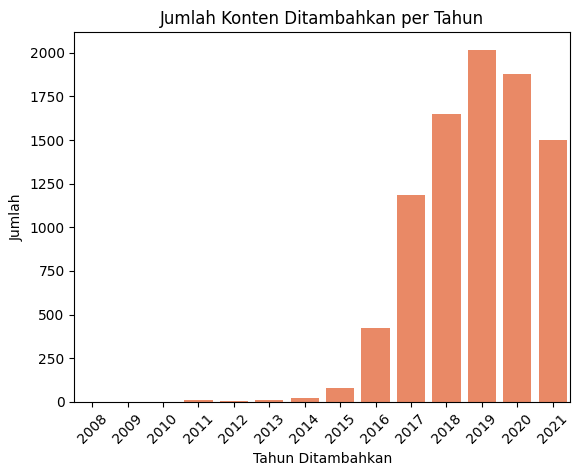

In [ ]:
# 10. Frekuensi penambahan konten berdasarkan waktu
df['year_added'] = df['date_added'].dt.year
plt.figure()
sns.countplot(data=df, x='year_added', color='coral')
plt.title('Jumlah Konten Ditambahkan per Tahun')
plt.xlabel('Tahun Ditambahkan')
plt.ylabel('Jumlah')
plt.xticks(rotation=45)
plt.show()

# Melakukan pemilihan kolom data yang akan di pilih yang sesuai dengan topik visualisasi yang akan di bawakan

In [ ]:
# Misalnya DataFrame kamu bernama df
columns_to_drop = ['director', 'duration', 'duration_int', 'duration_type', 'listed_in', 'year_added']

# Hapus kolom-kolom tersebut
df.drop(columns=columns_to_drop, inplace=True)

# Tampilkan sisa kolom untuk memastikan
print(df.columns)

Index(['type', 'title', 'country', 'date_added', 'release_year', 'rating'], dtype='object')


tahap ini dilakukan untuk mengefisiensikan load data yang akan masuk ke google looker

# Melakukan download data untuk step selanjutnya

In [ ]:
#df.to_excel('netflix1_bersih.xlsx', index=False)

In [ ]:
#from google.colab import files
#files.download('netflix1_bersih.xlsx')